1. Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


2. Loading the Dataset

In [2]:
df = pd.read_csv("employee_attrition_analysis_dataset.csv")

print("Dataset loaded successfully!")

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of Rows: 1500
Number of Columns: 26


,Employee_ID,Age,Gender,Marital_Status,Department,Job_Role,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Work_Life_Balance,Job_Satisfaction,Performance_Rating,Training_Hours_Last_Year,Overtime,Project_Count,Average_Hours_Worked_Per_Week,Absenteeism,Work_Environment_Satisfaction,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Attrition
0,1,58,Female,Married,IT,Manager,1,15488,28,15,4,2,1,3,4,14,No,6,54,17,4,4,4,20,3,No
1,2,48,Female,Married,Sales,Assistant,5,13079,28,6,9,1,2,1,1,6,Yes,2,45,1,4,1,2,25,2,No
2,3,34,Male,Married,Marketing,Assistant,1,13744,24,24,14,8,3,2,1,77,Yes,6,34,2,3,4,4,45,3,No
3,4,27,Female,Divorced,Marketing,Manager,1,6809,26,10,8,2,3,5,4,49,No,9,48,18,2,3,1,35,3,No
4,5,40,Male,Divorced,Marketing,Executive,1,10206,52,29,10,1,2,5,1,64,No,3,33,0,4,1,3,44,3,No


3. Understanding the Dataset

In [3]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Employee_ID                    1500 non-null   int64 
 1   Age                            1500 non-null   int64 
 2   Gender                         1500 non-null   object
 3   Marital_Status                 1500 non-null   object
 4   Department                     1500 non-null   object
 5   Job_Role                       1500 non-null   object
 6   Job_Level                      1500 non-null   int64 
 7   Monthly_Income                 1500 non-null   int64 
 8   Hourly_Rate                    1500 non-null   int64 
 9   Years_at_Company               1500 non-null   int64 
 10  Years_in_Current_Role          1500 non-null   int64 
 11  Years_Since_Last_Promotion     1500 non-null   int64 
 12  Work_Life_Balance              1500 non-n

In [4]:
print("Data Types of All Columns:")
display(df.dtypes.to_frame(name="Data Type"))

Data Types of All Columns:


,Data Type
Employee_ID,int64
Age,int64
Gender,object
Marital_Status,object
Department,object
Job_Role,object
Job_Level,int64
Monthly_Income,int64
Hourly_Rate,int64
Years_at_Company,int64


In [5]:
print("Statistical Summary of Numerical Columns:")
display(df.describe().T)

print("\nSummary of Categorical Columns:")
display(df.describe(include="object").T)

Statistical Summary of Numerical Columns:


,count,mean,std,min,25%,50%,75%,max
Employee_ID,1500.0,750.500000,433.157015,1.0,375.75,750.5,1125.25,1500.0
Age,1500.0,39.789333,11.709670,20.0,29.00,41.0,50.00,59.0
Job_Level,1500.0,3.052667,1.396851,1.0,2.00,3.0,4.00,5.0
Monthly_Income,1500.0,11605.540000,4881.361846,3001.0,7586.50,11514.0,15855.00,19999.0
Hourly_Rate,1500.0,57.478667,24.943730,15.0,35.00,58.0,79.00,99.0
Years_at_Company,1500.0,14.878667,8.263179,1.0,8.00,15.0,22.00,29.0
Years_in_Current_Role,1500.0,7.582000,4.007408,1.0,4.00,8.0,11.00,14.0
Years_Since_Last_Promotion,1500.0,4.425333,3.001516,0.0,2.00,4.0,7.00,9.0
Work_Life_Balance,1500.0,2.504000,1.107611,1.0,2.00,3.0,3.00,4.0
Job_Satisfaction,1500.0,3.139333,1.451892,1.0,2.00,3.0,4.00,5.0



Summary of Categorical Columns:


,count,unique,top,freq
Gender,1500,2,Male,761
Marital_Status,1500,3,Married,532
Department,1500,5,Finance,338
Job_Role,1500,4,Manager,415
Overtime,1500,2,No,776
Attrition,1500,2,No,1203


In [6]:
print("Statistical Summary of Numerical Columns:")
display(df.describe().T)

print("\nSummary of Categorical Columns:")
display(df.describe(include="object").T)

Statistical Summary of Numerical Columns:


,count,mean,std,min,25%,50%,75%,max
Employee_ID,1500.0,750.500000,433.157015,1.0,375.75,750.5,1125.25,1500.0
Age,1500.0,39.789333,11.709670,20.0,29.00,41.0,50.00,59.0
Job_Level,1500.0,3.052667,1.396851,1.0,2.00,3.0,4.00,5.0
Monthly_Income,1500.0,11605.540000,4881.361846,3001.0,7586.50,11514.0,15855.00,19999.0
Hourly_Rate,1500.0,57.478667,24.943730,15.0,35.00,58.0,79.00,99.0
Years_at_Company,1500.0,14.878667,8.263179,1.0,8.00,15.0,22.00,29.0
Years_in_Current_Role,1500.0,7.582000,4.007408,1.0,4.00,8.0,11.00,14.0
Years_Since_Last_Promotion,1500.0,4.425333,3.001516,0.0,2.00,4.0,7.00,9.0
Work_Life_Balance,1500.0,2.504000,1.107611,1.0,2.00,3.0,3.00,4.0
Job_Satisfaction,1500.0,3.139333,1.451892,1.0,2.00,3.0,4.00,5.0



Summary of Categorical Columns:


,count,unique,top,freq
Gender,1500,2,Male,761
Marital_Status,1500,3,Married,532
Department,1500,5,Finance,338
Job_Role,1500,4,Manager,415
Overtime,1500,2,No,776
Attrition,1500,2,No,1203


4. Data Cleaning and Preprocessing

In [7]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

display(missing_summary)
print("Total Missing Values:", df.isnull().sum().sum())

,Missing Values,Missing Percentage
Employee_ID,0,0.0
Age,0,0.0
Gender,0,0.0
Marital_Status,0,0.0
Department,0,0.0
Job_Role,0,0.0
Job_Level,0,0.0
Monthly_Income,0,0.0
Hourly_Rate,0,0.0
Years_at_Company,0,0.0


Total Missing Values: 0


In [8]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Employee IDs:", df["Employee_ID"].duplicated().sum())

Duplicate Rows: 0
Duplicate Employee IDs: 0


4.Data Cleaning and Preprocessing

In [9]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (1500, 26)
Working Dataset Shape: (1500, 26)


In [10]:
df_clean = df_clean.drop_duplicates()

df_clean = df_clean.drop_duplicates(
    subset=["Employee_ID"]
)

print("Dataset Shape After Removing Duplicates:", df_clean.shape)

Dataset Shape After Removing Duplicates: (1500, 26)


In [11]:
df_clean.columns = df_clean.columns.str.strip()

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

print("Unnecessary spaces handled successfully.")

Unnecessary spaces handled successfully.


In [12]:
print("Missing Values Before Treatment:")
print(df_clean.isnull().sum().sum())

for col in df_clean.select_dtypes(include=np.number).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include="object").columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

print("\nMissing Values After Treatment:")
print(df_clean.isnull().sum().sum())

Missing Values Before Treatment:
0

Missing Values After Treatment:
0


In [13]:
print("Attrition Categories:")
print(df_clean["Attrition"].value_counts(dropna=False))

print("\nAge Range:")
print(df_clean["Age"].min(), "-", df_clean["Age"].max())

print("\nMonthly Income Range:")
print(df_clean["Monthly_Income"].min(), "-", df_clean["Monthly_Income"].max())

print("\nYears at Company Range:")
print(df_clean["Years_at_Company"].min(), "-", df_clean["Years_at_Company"].max())

Attrition Categories:
Attrition
No     1203
Yes     297
Name: count, dtype: int64

Age Range:
20 - 59

Monthly Income Range:
3001 - 19999

Years at Company Range:
1 - 29


5. Exploratory Data Analysis

Employee Attrition Count:


Attrition
No     1203
Yes     297
Name: count, dtype: int64


Employee Attrition Percentage:


Attrition
No     80.2
Yes    19.8
Name: proportion, dtype: float64

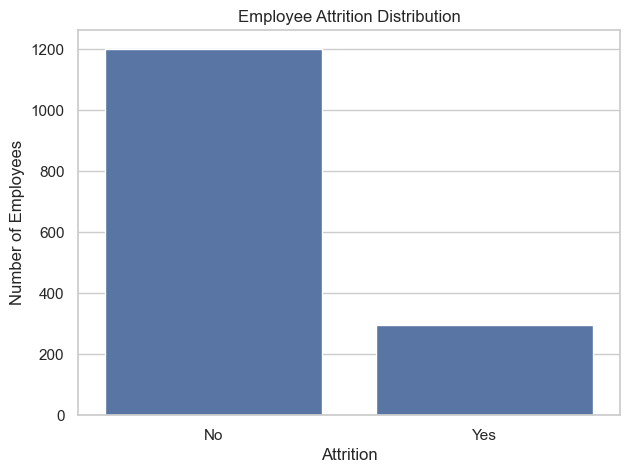

In [14]:
print("Employee Attrition Count:")
display(df_clean["Attrition"].value_counts())

print("\nEmployee Attrition Percentage:")
display(
    (df_clean["Attrition"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

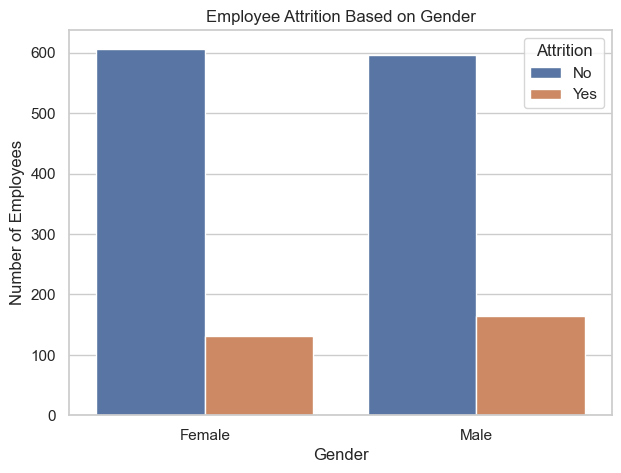

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Gender",
    hue="Attrition"
)

plt.title("Employee Attrition Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")
plt.show()

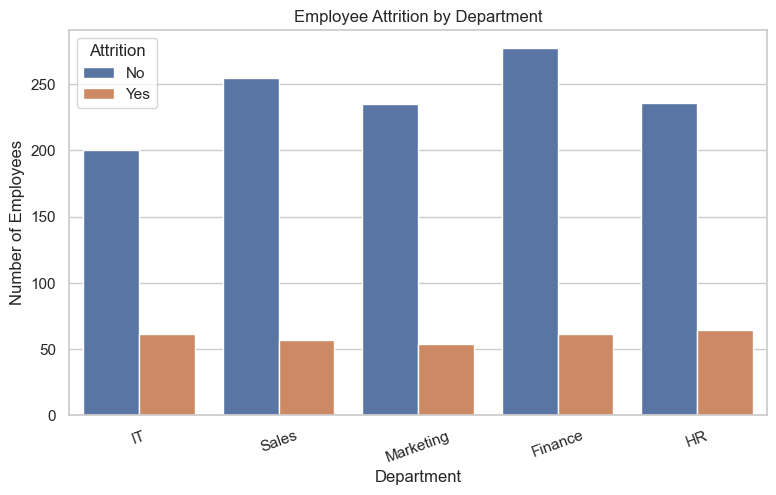

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Department",
    hue="Attrition"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=20)
plt.show()

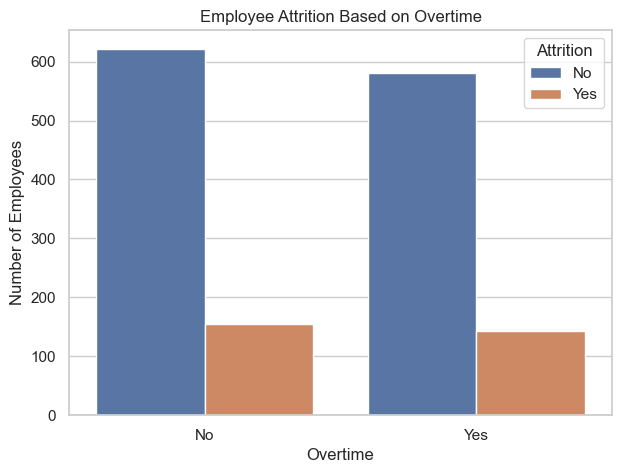

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Overtime",
    hue="Attrition"
)

plt.title("Employee Attrition Based on Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")
plt.show()

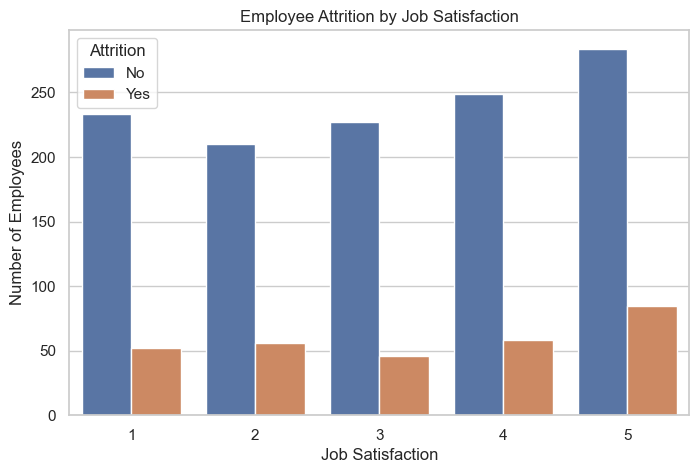

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Job_Satisfaction",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Satisfaction")
plt.xlabel("Job Satisfaction")
plt.ylabel("Number of Employees")
plt.show()

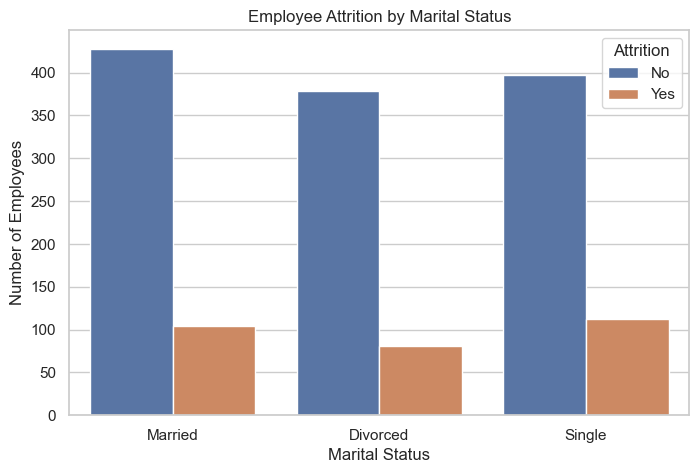

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Marital_Status",
    hue="Attrition"
)

plt.title("Employee Attrition by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Employees")
plt.show()

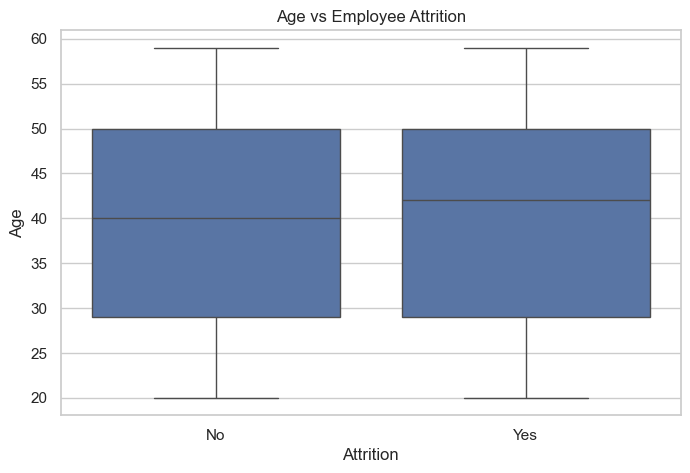

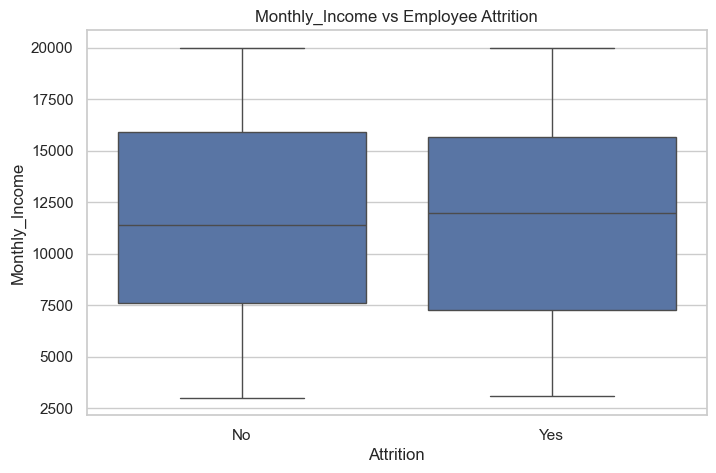

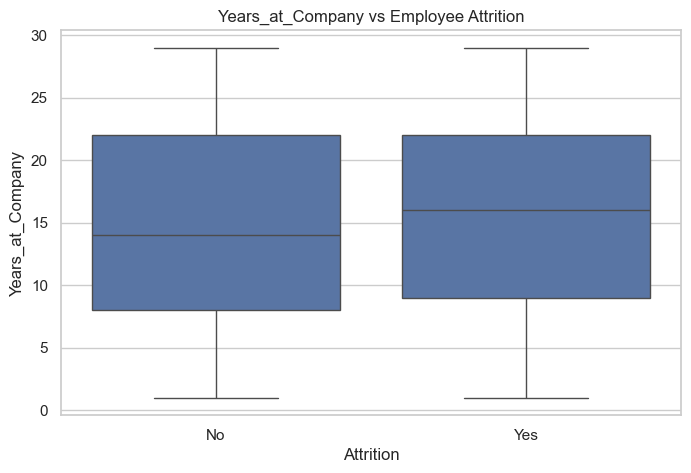

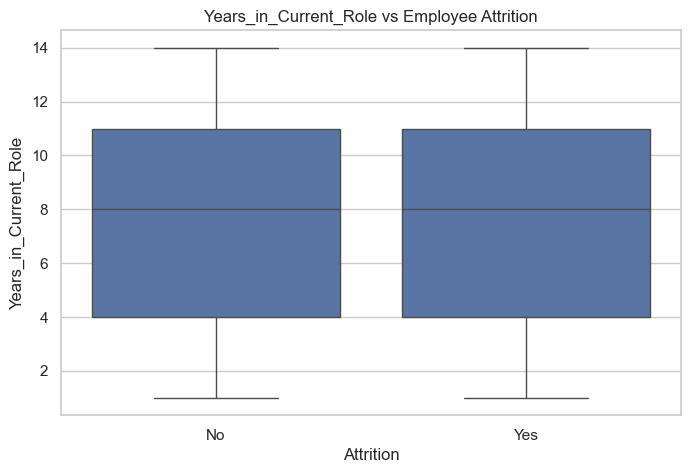

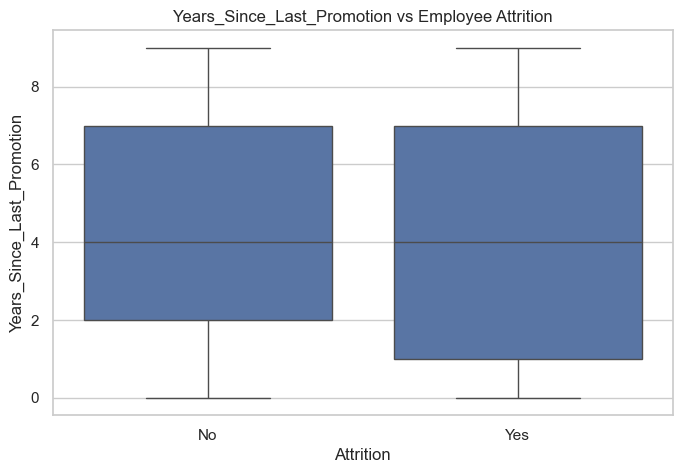

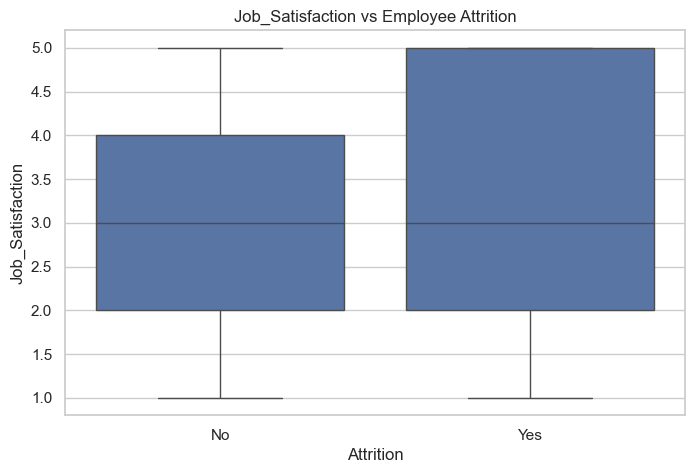

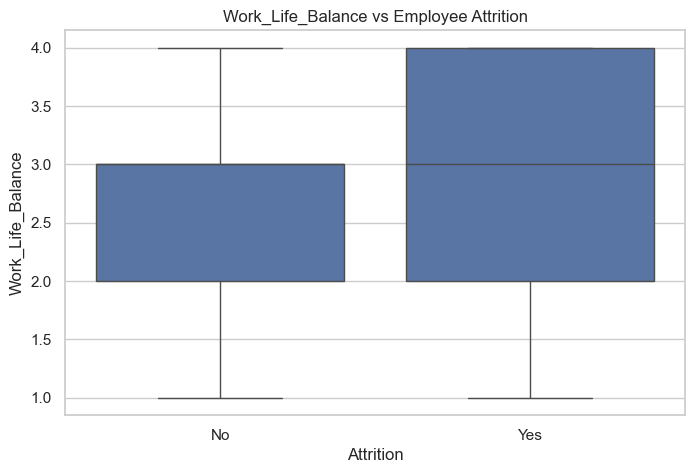

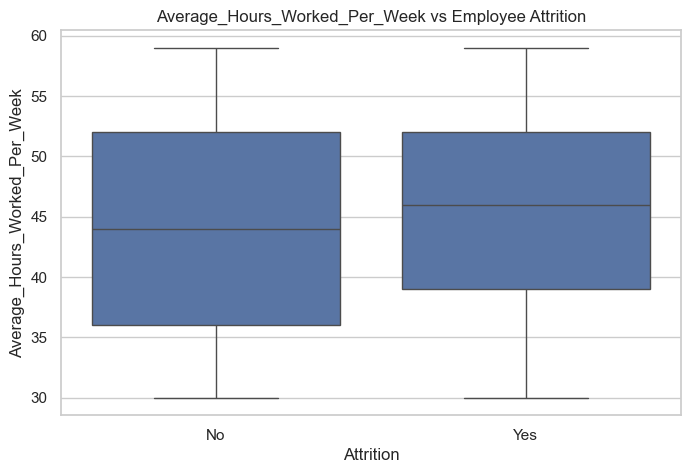

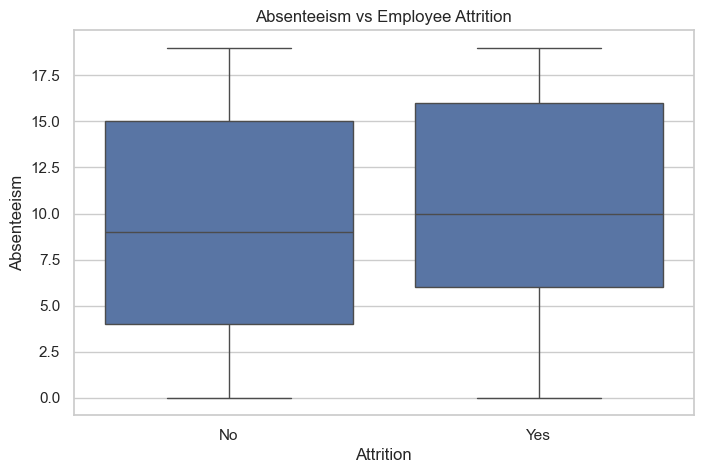

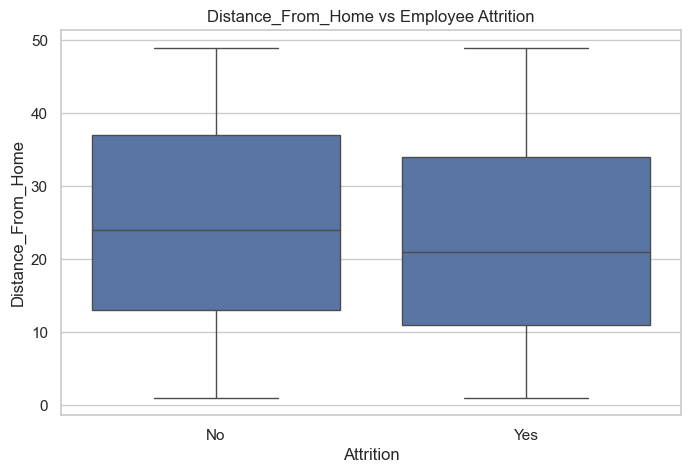

In [20]:
numerical_features = [
    "Age",
    "Monthly_Income",
    "Years_at_Company",
    "Years_in_Current_Role",
    "Years_Since_Last_Promotion",
    "Job_Satisfaction",
    "Work_Life_Balance",
    "Average_Hours_Worked_Per_Week",
    "Absenteeism",
    "Distance_From_Home"
]

numerical_features = [
    col for col in numerical_features
    if col in df_clean.columns
]

for col in numerical_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df_clean,
        x="Attrition",
        y=col
    )

    plt.title(f"{col} vs Employee Attrition")
    plt.xlabel("Attrition")
    plt.ylabel(col)

    plt.show()

Attrition,No,Yes
Department,,
Finance,81.95,18.05
HR,78.67,21.33
IT,76.63,23.37
Marketing,81.31,18.69
Sales,81.73,18.27


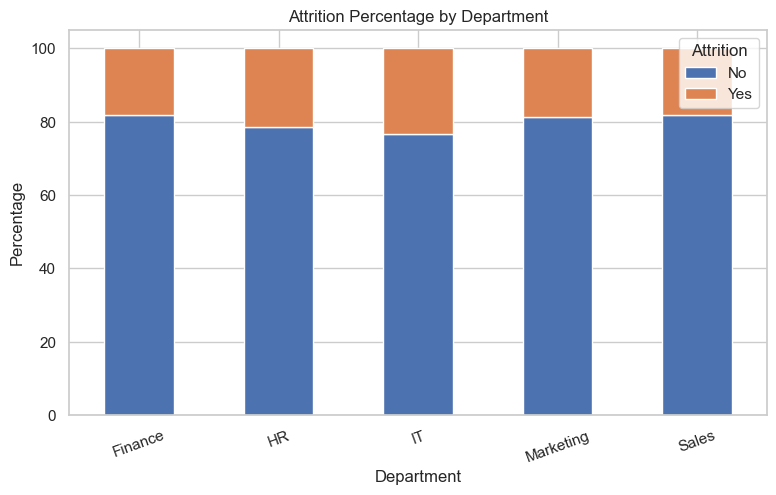

In [21]:
department_attrition = pd.crosstab(
    df_clean["Department"],
    df_clean["Attrition"],
    normalize="index"
) * 100

display(department_attrition.round(2))

department_attrition.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Attrition Percentage by Department")
plt.xlabel("Department")
plt.ylabel("Percentage")
plt.xticks(rotation=20)
plt.legend(title="Attrition")
plt.show()

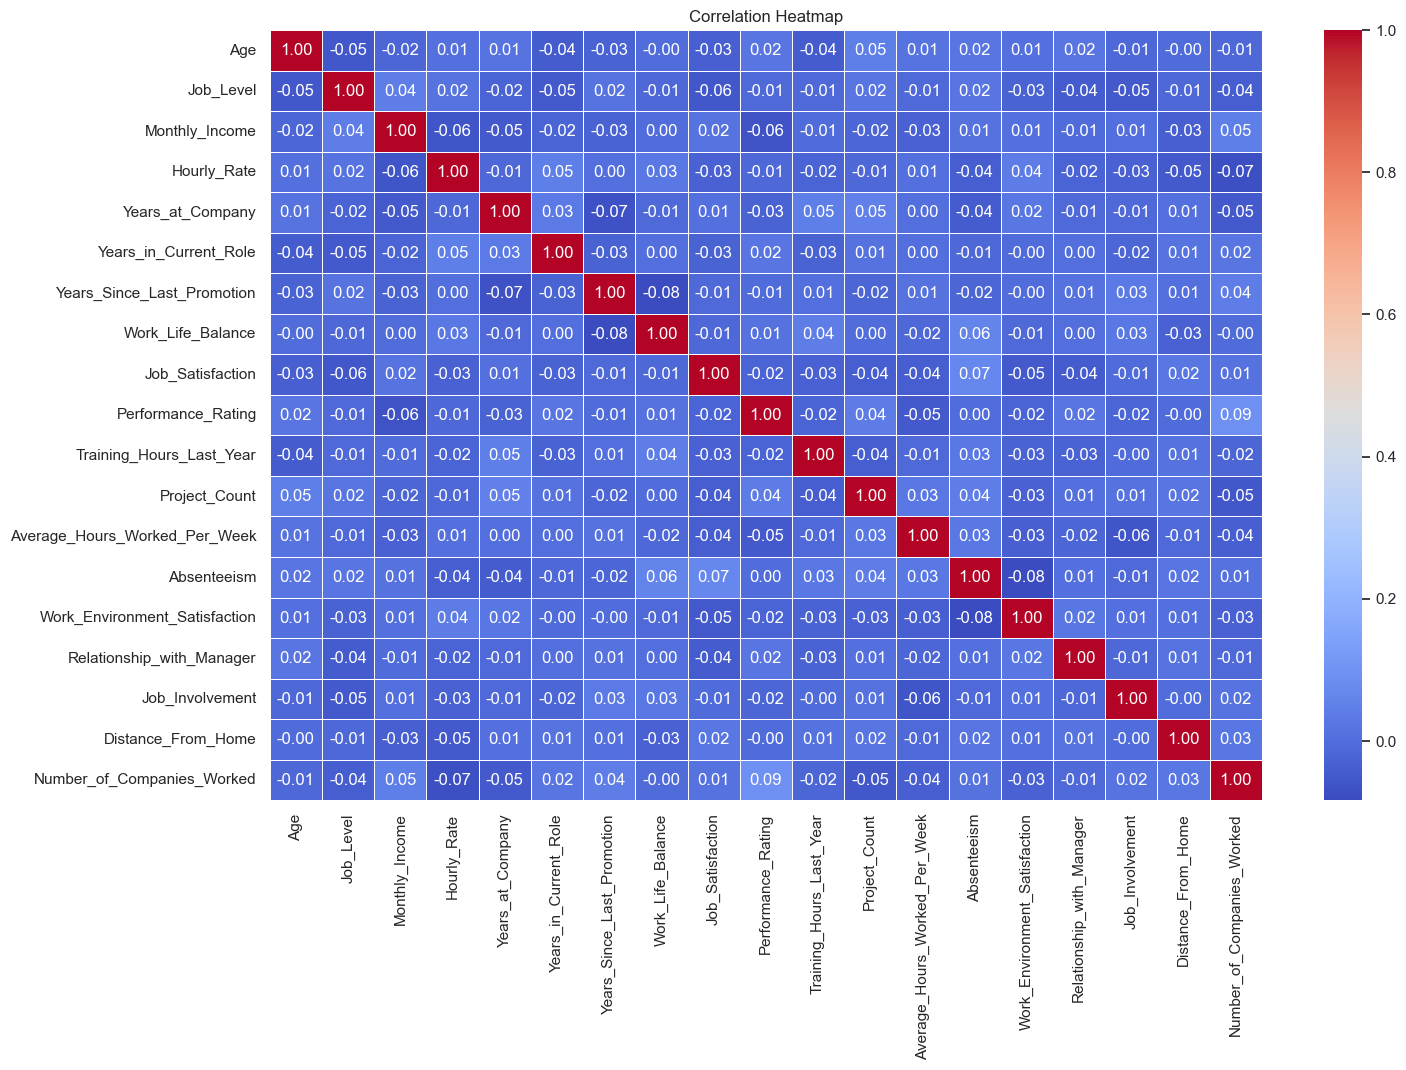

In [22]:
correlation_data = df_clean.select_dtypes(
    include=np.number
).drop(columns=["Employee_ID"], errors="ignore")

plt.figure(figsize=(16, 10))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

6. Diagnostic Analysis

In [23]:
categorical_features = [
    "Gender",
    "Marital_Status",
    "Department",
    "Job_Role",
    "Overtime"
]

categorical_features = [
    col for col in categorical_features
    if col in df_clean.columns
]

for col in categorical_features:

    print(f"\nAttrition Rate by {col}")

    result = df_clean.groupby(col, observed=True).agg(
        Total_Employees=("Attrition", "count"),
        Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
    )

    result["Attrition_Rate"] = (
        result["Employees_Left"] /
        result["Total_Employees"] * 100
    )

    display(result.round(2))


Attrition Rate by Gender


,Total_Employees,Employees_Left,Attrition_Rate
Gender,,,
Female,739,132,17.86
Male,761,165,21.68



Attrition Rate by Marital_Status


,Total_Employees,Employees_Left,Attrition_Rate
Marital_Status,,,
Divorced,459,81,17.65
Married,532,104,19.55
Single,509,112,22.00



Attrition Rate by Department


,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
Finance,338,61,18.05
HR,300,64,21.33
IT,261,61,23.37
Marketing,289,54,18.69
Sales,312,57,18.27



Attrition Rate by Job_Role


,Total_Employees,Employees_Left,Attrition_Rate
Job_Role,,,
Analyst,360,54,15.00
Assistant,344,80,23.26
Executive,381,84,22.05
Manager,415,79,19.04



Attrition Rate by Overtime


,Total_Employees,Employees_Left,Attrition_Rate
Overtime,,,
No,776,154,19.85
Yes,724,143,19.75


In [24]:
comparison = df_clean.groupby("Attrition")[
    numerical_features
].mean().T

display(comparison.round(2))

Attrition,No,Yes
Age,39.69,40.20
Monthly_Income,11607.32,11598.34
Years_at_Company,14.69,15.63
Years_in_Current_Role,7.61,7.46
Years_Since_Last_Promotion,4.50,4.11
Job_Satisfaction,3.12,3.23
Work_Life_Balance,2.50,2.53
Average_Hours_Worked_Per_Week,44.15,45.46
Absenteeism,9.44,10.41
Distance_From_Home,24.58,22.97


7. Statistical Analysis and Validation

In [25]:
%pip install statsmodels

In [26]:
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

chi_results = []

for col in categorical_features:

    contingency_table = pd.crosstab(
        df_clean[col],
        df_clean["Attrition"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    min_dimension = min(contingency_table.shape) - 1

    cramers_v = (
        np.sqrt(chi2 / (n * min_dimension))
        if min_dimension > 0 else np.nan
    )

    chi_results.append({
        "Feature": col,
        "Chi_Square": chi2,
        "P_Value": p_value,
        "Cramers_V": cramers_v
    })

chi_results_df = pd.DataFrame(chi_results)

chi_results_df["Adjusted_P_Value"] = multipletests(
    chi_results_df["P_Value"],
    method="fdr_bh"
)[1]

display(
    chi_results_df.sort_values("Adjusted_P_Value").round(4)
)

,Feature,Chi_Square,P_Value,Cramers_V,Adjusted_P_Value
3,Job_Role,9.1746,0.0271,0.0782,0.1353
0,Gender,3.2090,0.0732,0.0463,0.1831
1,Marital_Status,2.9179,0.2325,0.0441,0.3875
2,Department,3.8813,0.4223,0.0509,0.5279
4,Overtime,0.0000,1.0000,0.0000,1.0000


In [27]:
from scipy.stats import mannwhitneyu

mann_results = []

for col in numerical_features:

    yes = df_clean.loc[
        df_clean["Attrition"] == "Yes", col
    ].dropna()

    no = df_clean.loc[
        df_clean["Attrition"] == "No", col
    ].dropna()

    statistic, p_value = mannwhitneyu(
        yes,
        no,
        alternative="two-sided"
    )

    mann_results.append({
        "Feature": col,
        "Median_Yes": yes.median(),
        "Median_No": no.median(),
        "U_Statistic": statistic,
        "P_Value": p_value
    })

mann_results_df = pd.DataFrame(mann_results)

mann_results_df["Adjusted_P_Value"] = multipletests(
    mann_results_df["P_Value"],
    method="fdr_bh"
)[1]

display(
    mann_results_df.sort_values("Adjusted_P_Value").round(4)
)

,Feature,Median_Yes,Median_No,U_Statistic,P_Value,Adjusted_P_Value
7,Average_Hours_Worked_Per_Week,46.0,44.0,193894.0,0.0225,0.1124
8,Absenteeism,10.0,9.0,195335.5,0.0124,0.1124
4,Years_Since_Last_Promotion,4.0,4.0,165645.5,0.0506,0.1542
2,Years_at_Company,16.0,14.0,190456.5,0.0771,0.1542
9,Distance_From_Home,21.0,24.0,166652.0,0.0727,0.1542
5,Job_Satisfaction,3.0,3.0,186851.0,0.2099,0.3498
0,Age,42.0,40.0,183009.5,0.5138,0.7054
3,Years_in_Current_Role,8.0,8.0,175479.0,0.6349,0.7054
6,Work_Life_Balance,3.0,3.0,181804.0,0.6256,0.7054
1,Monthly_Income,11997.0,11415.0,178565.5,0.9905,0.9905


8. Feature Engineering and Selection

In [28]:
df_model = df_clean.copy()

df_model["Attrition"] = df_model["Attrition"].map({
    "No": 0,
    "Yes": 1
})

print("Target Variable Distribution:")
display(df_model["Attrition"].value_counts())

Target Variable Distribution:


Attrition
0    1203
1     297
Name: count, dtype: int64

In [29]:
X = df_model.drop(
    columns=["Attrition", "Employee_ID"]
)

y = df_model["Attrition"]

print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Independent Variables Shape: (1500, 24)
Dependent Variable Shape: (1500,)

Features:
['Age', 'Gender', 'Marital_Status', 'Department', 'Job_Role', 'Job_Level', 'Monthly_Income', 'Hourly_Rate', 'Years_at_Company', 'Years_in_Current_Role', 'Years_Since_Last_Promotion', 'Work_Life_Balance', 'Job_Satisfaction', 'Performance_Rating', 'Training_Hours_Last_Year', 'Overtime', 'Project_Count', 'Average_Hours_Worked_Per_Week', 'Absenteeism', 'Work_Environment_Satisfaction', 'Relationship_with_Manager', 'Job_Involvement', 'Distance_From_Home', 'Number_of_Companies_Worked']


Attrition
0    80.2
1    19.8
Name: proportion, dtype: float64

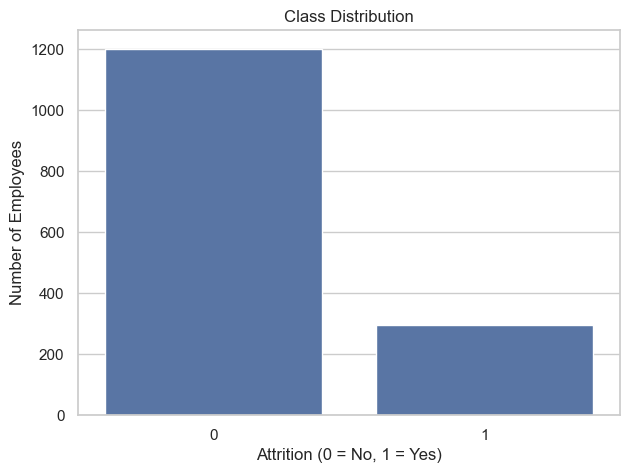

In [30]:
class_distribution = y.value_counts(normalize=True) * 100

display(class_distribution.round(2))

plt.figure(figsize=(7, 5))

sns.countplot(x=y)

plt.title("Class Distribution")
plt.xlabel("Attrition (0 = No, 1 = Yes)")
plt.ylabel("Number of Employees")
plt.show()

9. Splitting the Dataset 

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
display(y_test.value_counts(normalize=True).round(3))

Training Data: (1200, 24)
Testing Data: (300, 24)

Training Target Distribution:


Attrition
0    0.802
1    0.198
Name: proportion, dtype: float64


Testing Target Distribution:


Attrition
0    0.803
1    0.197
Name: proportion, dtype: float64

10. Data Preprocessing for Machine Learning

In [32]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_model = X_train.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features_model)

Numerical Features:
['Age', 'Job_Level', 'Monthly_Income', 'Hourly_Rate', 'Years_at_Company', 'Years_in_Current_Role', 'Years_Since_Last_Promotion', 'Work_Life_Balance', 'Job_Satisfaction', 'Performance_Rating', 'Training_Hours_Last_Year', 'Project_Count', 'Average_Hours_Worked_Per_Week', 'Absenteeism', 'Work_Environment_Satisfaction', 'Relationship_with_Manager', 'Job_Involvement', 'Distance_From_Home', 'Number_of_Companies_Worked']

Categorical Features:
['Gender', 'Marital_Status', 'Department', 'Job_Role', 'Overtime']


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features_model)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


11. Model Building and Comparision

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Baseline": DummyClassifier(strategy="prior"),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

print("Machine Learning Models Defined Successfully!")

Machine Learning Models Defined Successfully!


In [35]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1_Score": scores["test_f1"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1_Score",
        ascending=False
    ).round(3)
)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
3,Random Forest,0.893,1.000,0.458,0.627,0.790
2,Decision Tree,0.685,0.335,0.592,0.427,0.682
1,Logistic Regression,0.558,0.222,0.491,0.306,0.552
0,Baseline,0.802,0.000,0.000,0.000,0.500


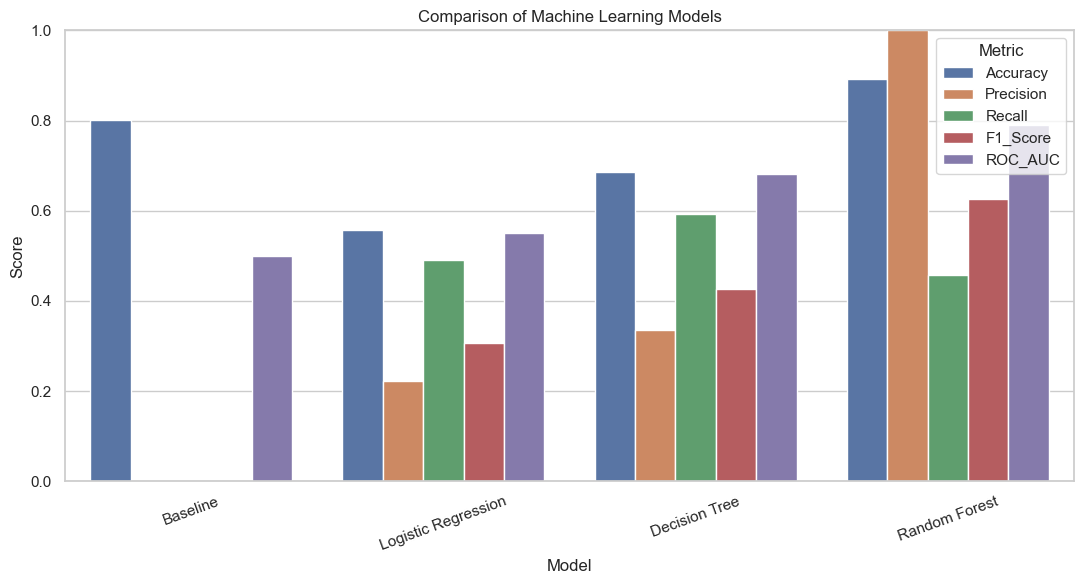

In [36]:
plt.figure(figsize=(11, 6))

results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Machine Learning Models")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

12. Model Evaluation

In [37]:
best_model_name = results_df.loc[
    results_df["F1_Score"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", models[best_model_name])
])

best_model.fit(X_train, y_train)

print("Best Model Trained Successfully!")

Best Model: Random Forest
Best Model Trained Successfully!


In [38]:
y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(X_test)[:, 1]

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


In [39]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("Model Evaluation Results")

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))
print("ROC-AUC:", round(roc_auc, 3))

Model Evaluation Results
Accuracy: 0.89
Precision: 1.0
Recall: 0.441
F1 Score: 0.612
ROC-AUC: 0.799


In [40]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

No Attrition       0.88      1.00      0.94       241
   Attrition       1.00      0.44      0.61        59

    accuracy                           0.89       300
   macro avg       0.94      0.72      0.77       300
weighted avg       0.90      0.89      0.87       300



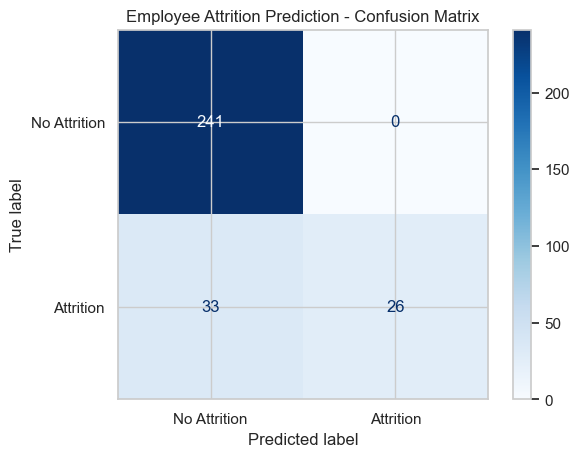

In [41]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["No Attrition", "Attrition"],
    cmap="Blues"
)

plt.title("Employee Attrition Prediction - Confusion Matrix")
plt.show()

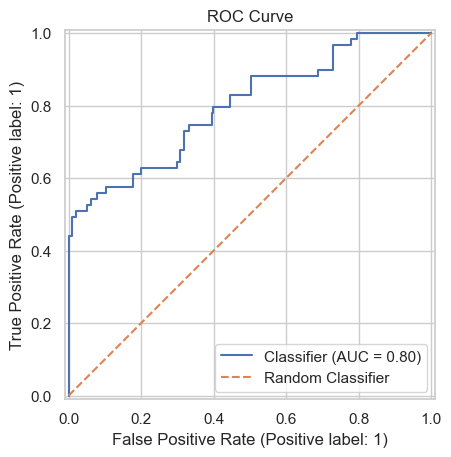

In [42]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve")
plt.legend()
plt.show()

13. Model Interpretability

In [43]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std_Dev": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15).round(4))

,Feature,Importance,Std_Dev
10,Years_Since_Last_Promotion,0.0232,0.0075
14,Training_Hours_Last_Year,0.0220,0.0103
17,Average_Hours_Worked_Per_Week,0.0206,0.0127
22,Distance_From_Home,0.0159,0.0039
12,Job_Satisfaction,0.0140,0.0048
1,Gender,0.0126,0.0050
6,Monthly_Income,0.0101,0.0063
5,Job_Level,0.0098,0.0045
3,Department,0.0092,0.0042
0,Age,0.0091,0.0070


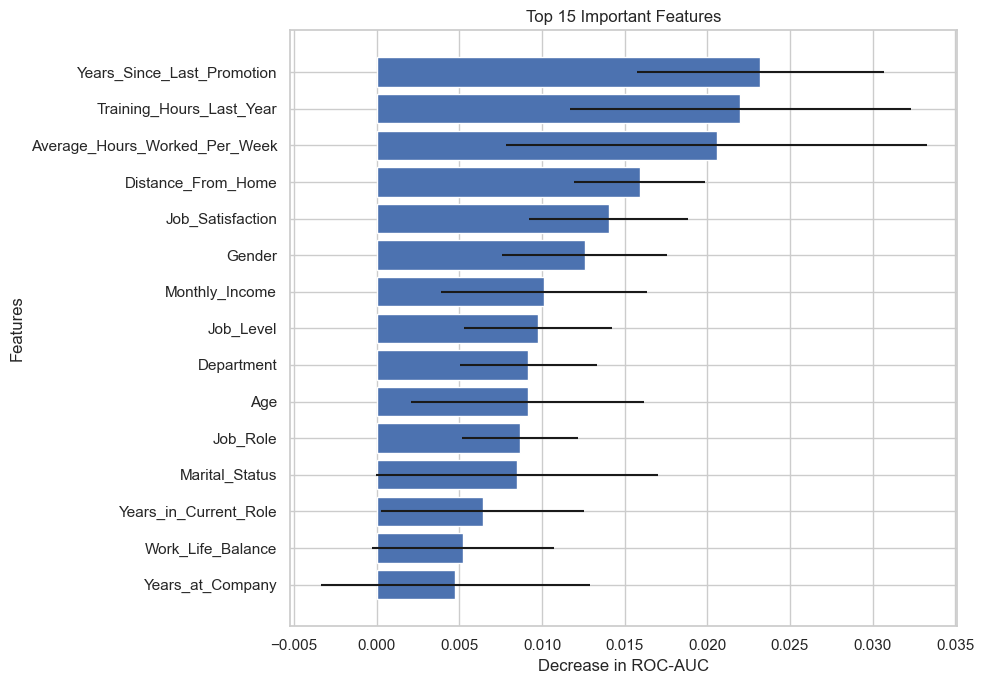

In [44]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std_Dev"]
)

plt.xlabel("Decrease in ROC-AUC")
plt.ylabel("Features")

plt.title("Top 15 Important Features")

plt.tight_layout()
plt.show()

15. Business Insights and Recommendations

In [45]:
business_features = [
    "Department",
    "Job_Role",
    "Overtime",
    "Job_Satisfaction",
    "Work_Life_Balance"
]

for col in business_features:

    if col not in df_clean.columns:
        continue

    summary = df_clean.groupby(
        col,
        observed=True
    ).agg(
        Total_Employees=("Attrition", "count"),
        Employees_Left=(
            "Attrition",
            lambda x: (x == "Yes").sum()
        )
    )

    summary["Attrition_Rate"] = (
        summary["Employees_Left"] /
        summary["Total_Employees"] * 100
    )

    summary = summary[
        summary["Total_Employees"] >= 30
    ]

    print(f"\nAttrition Analysis: {col}")

    display(
        summary.sort_values(
            by="Attrition_Rate",
            ascending=False
        ).round(2)
    )


Attrition Analysis: Department


,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
IT,261,61,23.37
HR,300,64,21.33
Marketing,289,54,18.69
Sales,312,57,18.27
Finance,338,61,18.05



Attrition Analysis: Job_Role


,Total_Employees,Employees_Left,Attrition_Rate
Job_Role,,,
Assistant,344,80,23.26
Executive,381,84,22.05
Manager,415,79,19.04
Analyst,360,54,15.00



Attrition Analysis: Overtime


,Total_Employees,Employees_Left,Attrition_Rate
Overtime,,,
No,776,154,19.85
Yes,724,143,19.75



Attrition Analysis: Job_Satisfaction


,Total_Employees,Employees_Left,Attrition_Rate
Job_Satisfaction,,,
5,369,85,23.04
2,266,56,21.05
4,307,58,18.89
1,285,52,18.25
3,273,46,16.85



Attrition Analysis: Work_Life_Balance


,Total_Employees,Employees_Left,Attrition_Rate
Work_Life_Balance,,,
4,361,80,22.16
2,363,75,20.66
1,371,72,19.41
3,405,70,17.28


15. Saving and Loading the Trained Model

In [46]:
import joblib

joblib.dump(
    best_model,
    "employee_attrition_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [47]:
loaded_model = joblib.load(
    "employee_attrition_model.pkl"
)

print("Saved Model Loaded Successfully!")

test_prediction = loaded_model.predict(X_test.iloc[[0]])

print(
    "Prediction:",
    "Yes" if test_prediction[0] == 1 else "No"
)

Saved Model Loaded Successfully!
Prediction: No


16. Exporting Results

In [48]:
sample_employee = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_employee)[0]

probability = loaded_model.predict_proba(
    sample_employee
)[0][1]

print("Employee Attrition Prediction")

print(
    "Prediction:",
    "Employee May Leave" if prediction == 1
    else "Employee May Stay"
)

print(
    "Estimated Attrition Probability:",
    round(probability * 100, 2), "%"
)

Employee Attrition Prediction
Prediction: Employee May Stay
Estimated Attrition Probability: 36.05 %


In [49]:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

chi_results_df.to_csv(
    "categorical_statistical_results.csv",
    index=False
)

mann_results_df.to_csv(
    "numerical_statistical_results.csv",
    index=False
)

print("All project results exported successfully!")

All project results exported successfully!


17. Conclusion

The Employee Attrition Prediction project focuses on analysing employee data to identify factors associated with employee turnover. Through data cleaning, exploratory data analysis, statistical validation and machine learning, the project develops a predictive model to estimate employee attrition. The findings can help organisations understand employee-related challenges and take data-driven steps to improve employee satisfaction and retention.